## Exercitiul 1 - Controlul calitatii intr-o fabrica

### a) Modelul probabilistic

Notam cu $\theta$ probabilitatea ca o componenta aleasa aleatoriu sa fie defecta.

Dintre $n=50$ de componente, $Y$ reprezinta numarul de componente defecte. Pentru o valoare data a lui $\theta$:

$$
Y\mid\theta \sim Binomial(50,\theta)
$$

Functia de verosimilitate este:

$$
P(Y=y\mid\theta)
=
{50\choose y}\theta^y(1-\theta)^{50-y}
$$

Cum au fost observate $y=8$ componente defecte:

$$
P(Y=8\mid\theta)
=
{50\choose 8}\theta^8(1-\theta)^{42}
$$

### b) Actualizarea Bayesiana

Distributia a priori este:

$$
\theta\sim Beta(2,18)
$$

Densitatea unui prior Beta este proportionala cu:

$$
p(\theta)
\propto
\theta^{\alpha-1}(1-\theta)^{\beta-1}
$$

Prin urmare, in cazul nostru:

$$
p(\theta)
\propto
\theta^{2-1}(1-\theta)^{18-1}
$$

Din punctul a), verosimilitatea este:

$$
p(y\mid\theta)
\propto
\theta^8(1-\theta)^{42}
$$

Folosind formula lui Bayes:

$$
p(\theta\mid y)
\propto
p(y\mid\theta)p(\theta)
$$

obtinem:

$$
p(\theta\mid y)
\propto
\theta^8(1-\theta)^{42}
\theta^{2-1}(1-\theta)^{18-1}
$$

$$
p(\theta\mid y)
\propto
\theta^{10-1}(1-\theta)^{60-1}
$$

Deci, prin conjugarea Beta-Binomial:

$$
\boxed{
\theta\mid Y=8\sim Beta(10,60)
}
$$

### c) Estimarea parametrului

Estimatorul de maxima verosimilitate este:

$$
\hat{\theta}_{MLE}
=
\frac{y}{n}
=
\frac{8}{50}
=
0.16
$$

Posteriorul este $Beta(10,60)$.

Pentru o distributie $Beta(a,b)$, modul distributiei, daca $a,b>1$, este:

$$
\hat{\theta}_{MAP}
=
\frac{a-1}{a+b-2}
$$

Prin urmare:

$$
\hat{\theta}_{MAP}
=
\frac{10-1}{10+60-2}
=
\frac{9}{68}
\approx
0.13235
$$

Media posteriorului este:

$$
E[\theta\mid Y=8]
=
\frac{10}{10+60}
=
\frac{10}{70}
\approx
0.14286
$$

Obtinem astfel:

$$
\boxed{
MLE=0.16,\quad MAP\approx0.13235,\quad E[\theta\mid Y=8]\approx0.14286
}
$$

Priorul $Beta(2,18)$ are media:

$$
\frac{2}{2+18}=0.10
$$

Datele observate indica o rata de defectare de $0.16$. Posteriorul combina informatia din prior cu datele, de aceea MAP si media posteriorului se afla intre valoarea sugerata de prior si MLE.

In [3]:
n = 50
y = 8

alpha_prior = 2
beta_prior = 18

alpha_post = alpha_prior + y
beta_post = beta_prior + n - y

mle = y / n
map_est = (alpha_post - 1) / (alpha_post + beta_post - 2)
media_post = alpha_post / (alpha_post + beta_post)

print("MLE =", mle)
print("MAP =", map_est)
print("Media posteriorului =", media_post)

MLE = 0.16
MAP = 0.1323529411764706
Media posteriorului = 0.14285714285714285


### d) Vizualizarea priorului si posteriorului

Comparam densitatea priorului $Beta(2,18)$ cu densitatea posteriorului $Beta(10,60)$.

Posteriorul incorporeaza cele 50 de observatii si este mai concentrat decat priorul. Datele observate au deplasat distributia de la o rata de defectare centrata in jurul valorii de $10\%$ spre valori mai apropiate de rata observata de $16\%$.

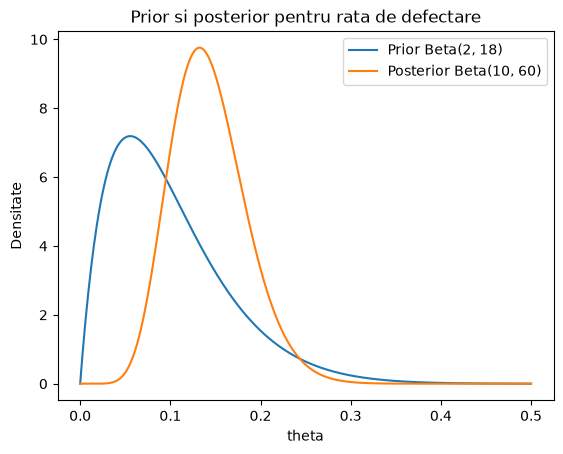

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

x = np.linspace(0, 0.5, 500)

prior = beta.pdf(x, 2, 18)
posterior = beta.pdf(x, 10, 60)

plt.plot(x, prior, label="Prior Beta(2, 18)")
plt.plot(x, posterior, label="Posterior Beta(10, 60)")

plt.xlabel("theta")
plt.ylabel("Densitate")
plt.title("Prior si posterior pentru rata de defectare")
plt.legend()

plt.show()

### e) HDI 95%

Posteriorul este:

$$
\theta\mid Y=8\sim Beta(10,60)
$$

Pentru HDI de $95\%$, calculam cuantilele $0.025$ si $0.975$ ale distributiei posterior.

Numeric obtinem aproximativ:

$$
\boxed{
[0.07175,\ 0.23322]
}
$$

Interpretare: conditionat de model, prior si datele observate, $95\%$ din probabilitatea posteriora a lui $\theta$ se afla intre aproximativ $7.2\%$ si $23.3\%$.

In [4]:
interval_95 = beta.ppf(
    [0.025, 0.975],
    alpha_post,
    beta_post
)

print("Interval credibil 95%:", interval_95)

Interval credibil 95%: [0.07174914 0.23321896]


### f) Probabilitatea ca rata de defectare sa fie sub 10%

Fabrica doreste:

$$
\theta<0.10
$$

Dorim deci sa calculam:

$$
P(\theta<0.10\mid Y=8)
$$

folosind distributia posterior $Beta(10,60)$.

Numeric obtinem:

$$
\boxed{
P(\theta<0.10\mid Y=8)\approx0.1484
}
$$

adica aproximativ $14.8\%$.

Prin urmare, datele nu sustin foarte puternic cerinta ca rata reala de defectare sa fie sub $10\%$.

In [5]:
prob_sub_10 = beta.cdf(
    0.10,
    alpha_post,
    beta_post
)

print("P(theta < 0.10 | Y=8) =", prob_sub_10)

P(theta < 0.10 | Y=8) = 0.14837323361352775


### g) Predictia Bayesiana

Se testeaza inca 10 componente produse in aceleasi conditii.

Pentru o valoare cunoscuta a lui $\theta$, probabilitatea ca niciuna dintre cele 10 componente sa nu fie defecta este:

$$
P(X=0\mid\theta)
=
(1-\theta)^{10}
$$

Deoarece $\theta$ nu este cunoscut exact, folosim distributia sa posteriora:

$$
P(X=0\mid Y=8)
=
\int_0^1
(1-\theta)^{10}
p(\theta\mid Y=8)\,d\theta
$$

Posteriorul este $Beta(10,60)$, deci:

$$
p(\theta\mid Y=8)
=
\frac{1}{B(10,60)}
\theta^9(1-\theta)^{59}
$$

Prin urmare:

$$
P(X=0\mid Y=8)
=
\frac{1}{B(10,60)}
\int_0^1
\theta^9(1-\theta)^{69}\,d\theta
$$

Integrala reprezinta functia Beta $B(10,70)$, deci:

$$
P(X=0\mid Y=8)
=
\frac{B(10,70)}{B(10,60)}
$$

Numeric:

$$
\boxed{
P(X=0\mid Y=8)\approx0.2360
}
$$

Asadar, probabilitatea predictiva ca urmatoarele 10 componente sa fie toate bune este de aproximativ $23.6\%$.

In [6]:
from scipy.special import beta as beta_function

prob_niciun_defect = (
    beta_function(10, 70)
    /
    beta_function(10, 60)
)

print(
    "Probabilitatea ca urmatoarele 10 componente sa fie toate bune =",
    prob_niciun_defect
)

Probabilitatea ca urmatoarele 10 componente sa fie toate bune = 0.23602209274442953
